# Tutorial 3
## Sigmoid, Classification, Hyperparameter Search and SGD


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
np.random.seed(42)


# 1. Sigmoid

-- Map values to something meaningful

Let's switch from a continuous target to **binary classification**.

The Breast Cancer dataset contains only two target labels:

- 0 = malignant
- 1 = benign

A linear model can produce a score:

$$z=wx+b$$

But $z$ can be any real number, so it cannot directly be interpreted as a probability.

The **sigmoid function** maps any real score into $(0,1)$:

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

Therefore logistic regression can use:

$$P(y=1|x)=\sigma(wx+b)$$



,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Target names: ['malignant' 'benign']


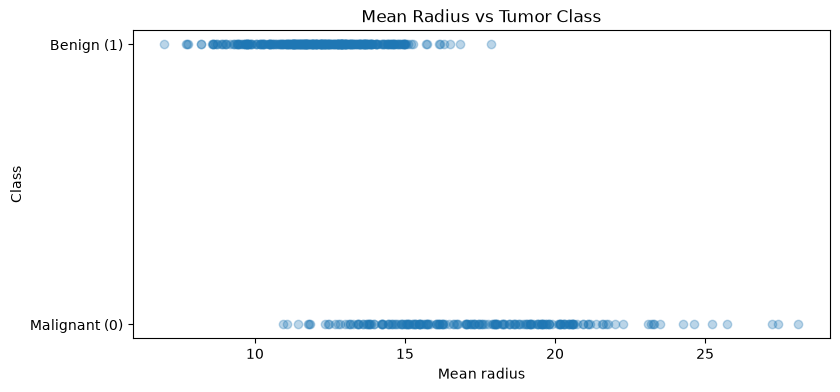

In [3]:
cancer = load_breast_cancer(as_frame=True)
cancer_df = cancer.frame

display(cancer_df.head())
print("Target names:", cancer.target_names)

X_cancer_raw = cancer_df["mean radius"].to_numpy()
y_cancer = cancer_df["target"].to_numpy()

plt.figure(figsize=(9, 4))
plt.scatter(X_cancer_raw, y_cancer, alpha=0.3)
plt.xlabel("Mean radius")
plt.ylabel("Class")
plt.yticks([0, 1], ["Malignant (0)", "Benign (1)"])
plt.title("Mean Radius vs Tumor Class")
plt.show()


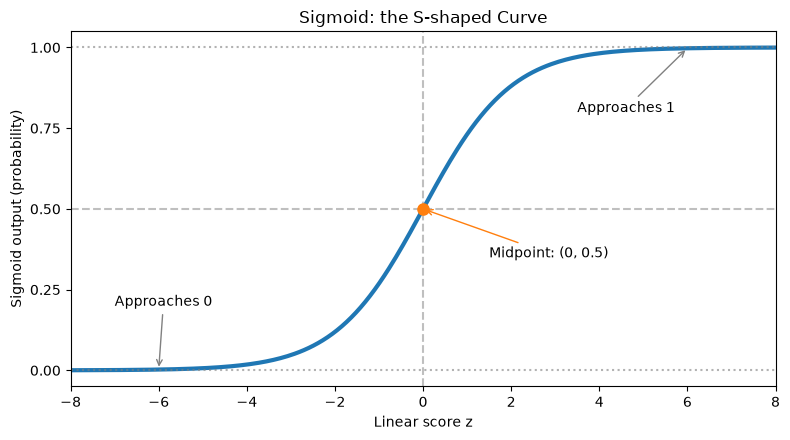

sigmoid(-4) = 0.0180
sigmoid( 0) = 0.5000
sigmoid( 4) = 0.9820


In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# The sigmoid maps any real score to a value between 0 and 1
z_values = np.linspace(-8, 8, 300)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(z_values, sigmoid(z_values), linewidth=3, color="tab:blue")
ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
ax.axhline(1, color="gray", linestyle=":", alpha=0.6)
ax.axhline(0.5, color="gray", linestyle="--", alpha=0.5)
ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
ax.scatter([0], [0.5], color="tab:orange", s=65, zorder=3)
ax.annotate("Midpoint: (0, 0.5)", xy=(0, 0.5), xytext=(1.5, 0.35),
            arrowprops={"arrowstyle": "->", "color": "tab:orange"})
ax.annotate("Approaches 0", xy=(-6, sigmoid(-6)), xytext=(-7, 0.2),
            arrowprops={"arrowstyle": "->", "color": "gray"})
ax.annotate("Approaches 1", xy=(6, sigmoid(6)), xytext=(3.5, 0.8),
            arrowprops={"arrowstyle": "->", "color": "gray"})
ax.set_xlabel("Linear score z")
ax.set_ylabel("Sigmoid output (probability)")
ax.set_title("Sigmoid: the S-shaped Curve")
ax.set_xlim(-8, 8)
ax.set_ylim(-0.05, 1.05)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
fig.tight_layout()
plt.show()

for value in [-4, 0, 4]:
    print(f"sigmoid({value:>2}) = {sigmoid(value):.4f}")


At $z=0$, sigmoid gives $0.5$.

A common rule is:

- probability $\geq 0.5$ → class 1
- probability $<0.5$ → class 0

# 2. Classification with Gradient Descent

Same algorithm. Two things change.

- The prediction goes through **sigmoid**
- The loss becomes **cross-entropy**

Let $\theta = \{w,b\}$. For each input we score and squash.

$$\hat{y} = \sigma(z) = \sigma(wx+b) = P(y=1\mid x)$$

## Loss Function

MSE is a poor fit here. We want to reward assigning high probability to the correct class.

For one observation

$$p(y\mid x) = \hat{y}^{\,y}(1-\hat{y})^{1-y}$$

Take the log and negate it. Maximizing likelihood is minimizing negative log-likelihood.

$$L_{CE}(\hat{y},y) = -\left[y\log(\hat{y}) + (1-y)\log(1-\hat{y})\right]$$

Average over the dataset for $L(\theta)$.

## Gradients

$$\frac{\partial L}{\partial w} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}^{(i)}-y^{(i)})x^{(i)}$$

$$\frac{\partial L}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}^{(i)}-y^{(i)})$$

Then update:

$$\theta \leftarrow \theta - \eta \nabla_{\theta}L$$


In [5]:
w_cls = 0.0
b_cls = 0.0

# scale feature to make gradient descent easier
X_cancer = (X_cancer_raw - X_cancer_raw.mean()) / X_cancer_raw.std()
learning_rate = 0.1
epochs = 1500
n = len(X_cancer)
loss_history = []
eps = 1e-12

for epoch in range(epochs):
    z = w_cls * X_cancer + b_cls
    y_hat = sigmoid(z)
    loss = -np.mean(y_cancer * np.log(y_hat + eps)+(1 - y_cancer) * np.log(1 - y_hat + eps))
    loss_history.append(loss)
    dw = (1 / n) * np.sum((y_hat - y_cancer) * X_cancer)
    db = (1 / n) * np.sum(y_hat - y_cancer)
    w_cls = w_cls - learning_rate * dw
    b_cls = b_cls - learning_rate * db

z = w_cls * X_cancer + b_cls
final_prob = sigmoid(z)
final_pred = (final_prob >= 0.5).astype(int)

accuracy = np.mean(final_pred == y_cancer)

print(f"Learned w = {w_cls:.3f}")
print(f"Learned b = {b_cls:.3f}")
print(f"Final loss = {loss_history[-1]:.3f}")
print(f"Training accuracy = {accuracy:.3f}")

Learned w = -3.526
Learned b = 0.643
Final loss = 0.290
Training accuracy = 0.880


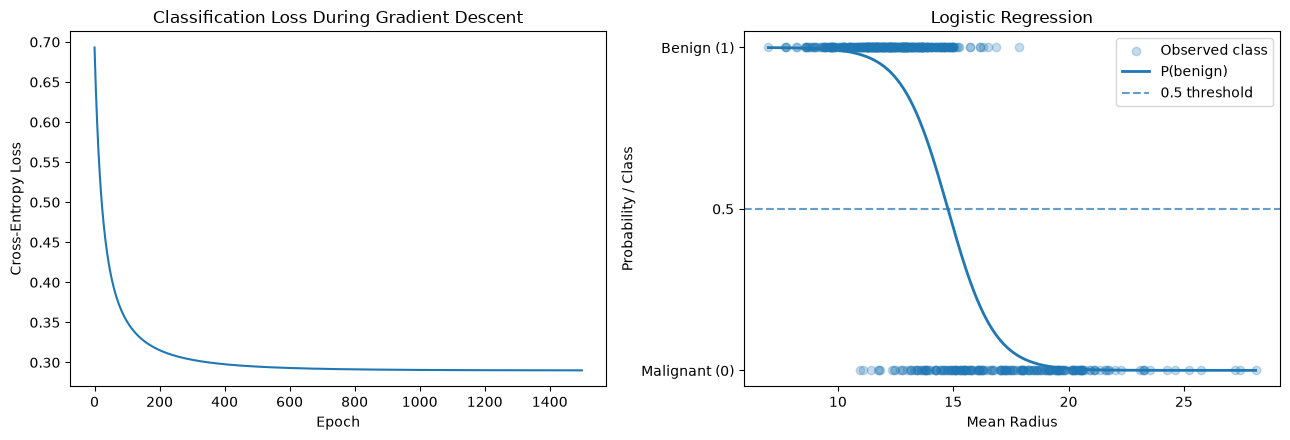

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(loss_history)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Classification Loss During Gradient Descent")
radius_grid = np.linspace(X_cancer_raw.min(),X_cancer_raw.max(),300)
radius_scaled = (radius_grid - X_cancer_raw.mean()) / X_cancer_raw.std()
z_grid = w_cls * radius_scaled + b_cls
prob_grid = sigmoid(z_grid)
axes[1].scatter(X_cancer_raw,y_cancer,alpha=0.25,label="Observed class")
axes[1].plot(radius_grid,prob_grid,linewidth=2,label="P(benign)")
axes[1].axhline(0.5,linestyle="--",alpha=0.7,label="0.5 threshold")
axes[1].set_xlabel("Mean Radius")
axes[1].set_ylabel("Probability / Class")
axes[1].set_yticks([0, 0.5, 1])
axes[1].set_yticklabels(["Malignant (0)","0.5","Benign (1)"])
axes[1].set_title("Logistic Regression")
axes[1].legend()

plt.tight_layout()
plt.show()

The accuracy above is **training accuracy**: the model was evaluated on the same examples it learned from. It does not estimate performance on unseen data. Later we will split the cancer dataset before scaling or training.

**Discuss:** Increasing the classification threshold reduces the number of predictions labeled benign. How does that affect different kinds of classification errors?


# 3. Hyperparameter Search (Review)

We use the synthetic happiness/GDP example from Tutorial 2, reproduced below.

Polynomial **degree** is a hyperparameter. Instead of choosing it by eye:

1. Train on a training set.
2. Compare degrees on a validation set.
3. Choose the best validation result.
4. Refit the chosen degree on training + validation data, then evaluate once on the held-out test set.

**Why not choose the setting with the smallest training loss?**

Because the most flexible setting may fit the training data extremely well but generalize poorly.

We will do a simple **grid search**: try each candidate degree and compare validation MSE.

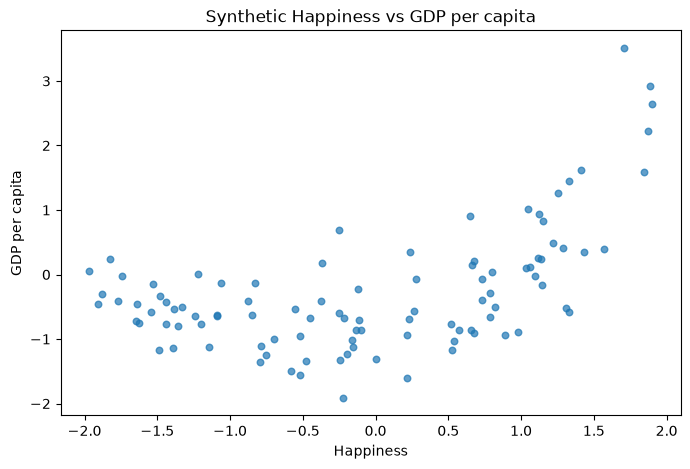

In [7]:
happiness = np.array([
    -1.97055092, -1.90915171, -1.87672866, -1.82478494, -1.76678903,
    -1.74473098, -1.64940032, -1.63980856, -1.62329061, -1.54187971,
    -1.52797639, -1.48754547, -1.48031398, -1.44099007, -1.44081201,
    -1.39075159, -1.38284203, -1.35491288, -1.33210832, -1.24211456,
    -1.22144517, -1.20036719, -1.14166131, -1.09236260, -1.09104511,
    -1.06424206, -0.87446443, -0.84668758, -0.82562497, -0.79395164,
    -0.78419961, -0.75053343, -0.69669857, -0.58189613, -0.55274956,
    -0.51816118, -0.51680790, -0.47591510, -0.45008648, -0.37445255,
    -0.36588543, -0.25313044, -0.25139232, -0.24448624, -0.22634320,
    -0.21537490, -0.19845625, -0.16433690, -0.15249108, -0.13311599,
    -0.12177675, -0.11561518, -0.09718030,  0.00417910,  0.21431760,
     0.21833915,  0.22812861,  0.23682864,  0.26094443,  0.27496478,
     0.52113037,  0.52665760,  0.53887328,  0.57546048,  0.64766606,
     0.65725416,  0.65940343,  0.67361185,  0.67925598,  0.72998202,
     0.73219581,  0.78528150,  0.78947212,  0.80106041,  0.82066151,
     0.88943740,  0.97904862,  1.03235096,  1.04455881,  1.05999543,
     1.09582419,  1.11353399,  1.12291612,  1.13559284,  1.14425722,
     1.14769751,  1.21905743,  1.25608154,  1.29104645,  1.31052469,
     1.32903921,  1.33071278,  1.41361229,  1.43439168,  1.57248449,
     1.70705996,  1.84759066,  1.87003893,  1.88279210,  1.90248941
])

gdp = np.array([
     0.05648254, -0.45859101, -0.30735330,  0.24127135, -0.40527416,
    -0.02564390, -0.72527023, -0.46004121, -0.75467209, -0.58837338,
    -0.14227329, -1.17197014, -0.33086415, -0.43346843, -0.76294061,
    -1.13955708, -0.53573092, -0.79587780, -0.50050835, -0.63565722,
     0.01398119, -0.76634060, -1.12923467, -0.63746185, -0.62043741,
    -0.13675998, -0.41048917, -0.63293816, -0.13101931, -1.35480736,
    -1.10452724, -1.24633994, -1.00729769, -1.49845424, -0.52865255,
    -0.94587010, -1.55562409, -1.33737673, -0.68144138, -0.41077876,
     0.17397256,  0.68355760, -0.60250482, -1.32480719, -1.91433676,
    -0.67034764, -1.22852985, -1.01553267, -1.11643148, -0.86454157,
    -0.22478335, -0.70279640, -0.86482889, -1.30821704, -1.59913282,
    -0.93012038, -0.68220957,  0.34907255, -0.56108957, -0.06959914,
    -0.76819190, -1.17086656, -1.03293042, -0.86604063,  0.91072550,
    -0.86630177,  0.14105014, -0.90382525,  0.21555271, -0.07202623,
    -0.40214614, -0.28453078, -0.66082060,  0.03157743, -0.51007843,
    -0.93264937, -0.88704790,  0.09534942,  1.01513632,  0.11760952,
    -0.02323617,  0.25989600,  0.93624384,  0.24218684, -0.16016772,
     0.83708186,  0.48060181,  1.26404954,  0.40784960, -0.51188309,
    -0.58725514,  1.44672043,  1.61860820,  0.34946445,  0.39864041,
     3.51111094,  1.59453004,  2.22013650,  2.91568190,  2.64993435
])

plt.figure(figsize=(8, 5))
plt.scatter(happiness ,gdp, s=22, alpha=0.7)
plt.xlabel("Happiness")
plt.ylabel("GDP per capita")
plt.title("Synthetic Happiness vs GDP per capita")
plt.show()

In [8]:
X_happy = happiness.reshape(-1, 1)
X_temp, X_test, y_temp, y_test = train_test_split( X_happy, gdp, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val = train_test_split( X_temp, y_temp, test_size=0.25, random_state=42)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Train: 60
Validation: 20
Test: 20


### Training error vs validation error


As degree increases, what do you expect the **training MSE** to do? Does the **validation MSE** have to do the same thing?

Best polynomial degree: 2


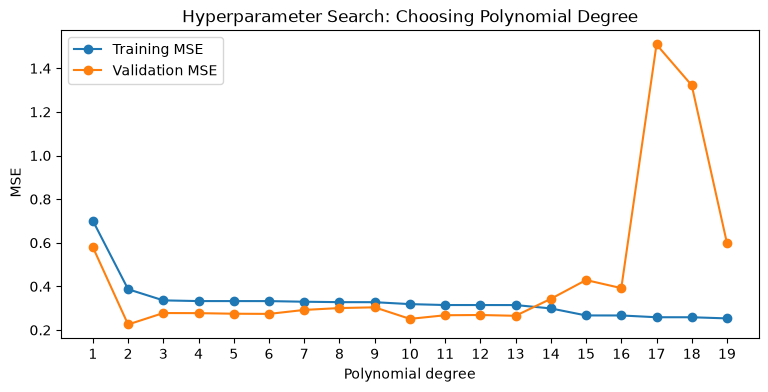

In [9]:
degrees_to_try = range(1, 20)
validation_mse = []
train_mse_list = []
for degree in degrees_to_try:
    X_poly_train = np.column_stack([X_train**d for d in range(degree + 1)])
    beta, _, _, _ = np.linalg.lstsq(X_poly_train, y_train, rcond=None)

    train_pred = X_poly_train.dot(beta)
    train_mse = np.mean((train_pred - y_train) ** 2)

    X_poly_val = np.column_stack([X_val**d for d in range(degree + 1)])
    val_pred = X_poly_val.dot(beta)
    val_mse = np.mean((val_pred - y_val) ** 2)

    train_mse_list.append(train_mse)
    validation_mse.append(val_mse)

best_degree = list(degrees_to_try)[int(np.argmin(validation_mse))]
print("Best polynomial degree:", best_degree)

plt.figure(figsize=(9, 4))
plt.plot(list(degrees_to_try), train_mse_list, marker="o", label="Training MSE")
plt.plot(list(degrees_to_try), validation_mse, marker="o", label="Validation MSE")
#plt.axvline(best_degree, linestyle="--", color="r", label="Best
plt.xlabel("Polynomial degree")
plt.ylabel(" MSE")
plt.title("Hyperparameter Search: Choosing Polynomial Degree")
plt.xticks(list(degrees_to_try))
plt.legend()
plt.show()



In [10]:
# refit the selected degree on training + validation data.
X_poly_temp = np.column_stack([X_temp**d for d in range(best_degree + 1)])
beta_final, _, _, _ = np.linalg.lstsq(X_poly_temp, y_temp, rcond=None)
X_poly_test = np.column_stack([X_test**d for d in range(best_degree + 1)])
print("Polynomial model test MSE:", np.mean((X_poly_test @ beta_final - y_test) ** 2))


Polynomial model test MSE: 0.3092320298640462


# 4. Stochastic Gradient Descent (SGD)

So far, each gradient update used every training example. That is **full-batch gradient descent**. With a large dataset, computing one update can be expensive.

| Method | Examples per update | Updates per epoch |
| --- | --- | --- |
| Full-batch gradient descent | All $n$ examples | 1 |
| Stochastic gradient descent | 1 example | $n$ |
| Mini-batch gradient descent | A small batch of $B$ examples | $\lceil n/B \rceil$ |


An **epoch** is one pass through the training set. Shuffle the training examples each epoch so updates do not always follow the same order.

For logistic regression, one example gives:

$$p_i=\sigma(wx_i+b),\qquad g_w=(p_i-y_i)x_i,\qquad g_b=p_i-y_i.$$

Update immediately:

$$w\leftarrow w-\eta g_w,\qquad b\leftarrow b-\eta g_b.$$

For a mini-batch, average these gradients over the examples in that batch. Individual updates are noisy, so loss need not decrease on every update or even every epoch. A smaller or decaying learning rate can help.

We will use the same cancer feature, split the data first, and estimate scaling parameters from **training data only**. Learning rate, batch size, and epoch count are hyperparameters; $w$ and $b$ are learned parameters.


In [11]:
x_train_raw, x_holdout_raw, y_sgd_train, y_holdout = train_test_split(
    X_cancer_raw, y_cancer, test_size=0.4, random_state=42, stratify=y_cancer
)
x_val_raw, x_test_raw, y_sgd_val, y_sgd_test = train_test_split(
    x_holdout_raw, y_holdout, test_size=0.5, random_state=42, stratify=y_holdout
)
train_mean, train_std = x_train_raw.mean(), x_train_raw.std()
x_sgd_train = (x_train_raw - train_mean) / train_std
x_sgd_val = (x_val_raw - train_mean) / train_std
x_sgd_test = (x_test_raw - train_mean) / train_std

# Stable sigmoid and cross entropy
def stable_sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))

def cross_entropy(x, y, w, b):
    z = w * x + b
    return np.mean(np.logaddexp(0, z) - y * z)

def fit_logistic_batches(x, y, learning_rate, epochs, batch_size, seed=42):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    history = []
    for epoch in range(epochs):
        order = rng.permutation(len(x))
        for start in range(0, len(x), batch_size):
            batch = order[start:start + batch_size]
            errors = stable_sigmoid(w * x[batch] + b) - y[batch]
            dw = np.mean(errors * x[batch])
            db = np.mean(errors)
            w -= learning_rate * dw
            b -= learning_rate * db
        history.append(cross_entropy(x, y, w, b))
    return w, b, np.array(history)

print("Train / validation / test:", len(x_sgd_train), len(x_sgd_val), len(x_sgd_test))


Train / validation / test: 341 114 114


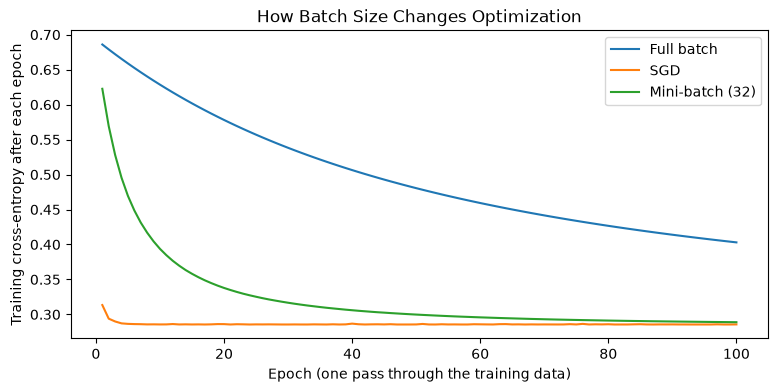

In [12]:
epochs_sgd = 100
plt.figure(figsize=(9, 4))
for label, batch_size in [("Full batch", len(x_sgd_train)), ("SGD", 1), ("Mini-batch (32)", 32)]:
    _, _, history = fit_logistic_batches(
        x_sgd_train, y_sgd_train, learning_rate=0.05,
        epochs=epochs_sgd, batch_size=batch_size
    )
    plt.plot(np.arange(1, epochs_sgd + 1), history, label=label)
plt.xlabel("Epoch (one pass through the training data)")
plt.ylabel("Training cross-entropy after each epoch")
plt.title("How Batch Size Changes Optimization")
plt.legend()
plt.show()


All 3 runs use the same learning rate and number of epochs, but different numbers of updates.


## Random search: learning rate and batch size

The polynomial example used grid search. We now use **random search** to tune the logistic classifier trained above, using two hyperparameters:

- **Learning rate:** sampled between 0.001 and 0.1, uniformly in log space to explore different orders of magnitude.
- **Batch size:** sampled from 1, 8, 16, 32, and 64. A batch size of 1 gives SGD; larger values give mini-batch gradient descent.

Try 60 combinations, each for 100 epochs, using the same training/validation split and shuffle seed. Keep every model's weights and its training and validation cross-entropy. Select using validation loss only. The cancer test split has not been used to choose any settings.

Each trial uses the same number of passes through the data, but smaller batches produce more updates per epoch. This explores performance under a fixed epoch budget, not equal running time. These hyperparameters change how we train the model; the model still predicts with sigmoid.


In [13]:
import pandas as pd

search_rng = np.random.default_rng(42)
n_trials = 60
trial_records = []
trial_models = {}

for trial_id in range(1, n_trials + 1):
    lr = float(10 ** search_rng.uniform(-3, -1))
    batch_size = int(search_rng.choice([1, 8, 16, 32, 64]))
    w_trial, b_trial, _ = fit_logistic_batches(
        x_sgd_train, y_sgd_train, learning_rate=lr,
        epochs=epochs_sgd, batch_size=batch_size, seed=42
    )
    trial_models[trial_id] = {"w": w_trial, "b": b_trial,
                              "mean": train_mean, "std": train_std}
    trial_records.append({
        "trial_id": trial_id,
        "learning_rate": lr,
        "batch_size": batch_size,
        "epochs": epochs_sgd,
        "seed": 42,
        "train_loss": cross_entropy(x_sgd_train, y_sgd_train, w_trial, b_trial),
        "validation_loss": cross_entropy(x_sgd_val, y_sgd_val, w_trial, b_trial),
    })

search_results = pd.DataFrame(trial_records)
leaderboard = search_results.sort_values("validation_loss").reset_index(drop=True)
display(leaderboard)
best_trial = leaderboard.iloc[0]
best_trial_id = int(best_trial["trial_id"])
best_search_model = trial_models[best_trial_id]
print("Selected trial:", best_trial_id)

,trial_id,learning_rate,batch_size,epochs,seed,train_loss,validation_loss
0,39,0.013724,1,100,42,0.285578,0.264694
1,20,0.023233,1,100,42,0.285585,0.264709
2,60,0.010048,1,100,42,0.285577,0.264714
3,29,0.025150,1,100,42,0.285588,0.264714
4,8,0.071372,8,100,42,0.285577,0.264718
5,58,0.027843,1,100,42,0.285594,0.264723
6,18,0.008579,1,100,42,0.285577,0.264748
7,49,0.050910,1,100,42,0.285714,0.264866
8,30,0.046187,8,100,42,0.285590,0.264988
9,13,0.045213,8,100,42,0.285593,0.265013


Selected trial: 39


## Visualize the search space in 3D

Each point represents one trial: **log10(learning rate)** on the first axis, **batch size** on the second, and **validation cross-entropy** on the third. Lower points perform better on validation data. The red star marks the winner.

These sampled points show part of the search space, not a complete surface. Batch size is discrete. Untested combinations may perform differently, and another shuffle seed can change the results.


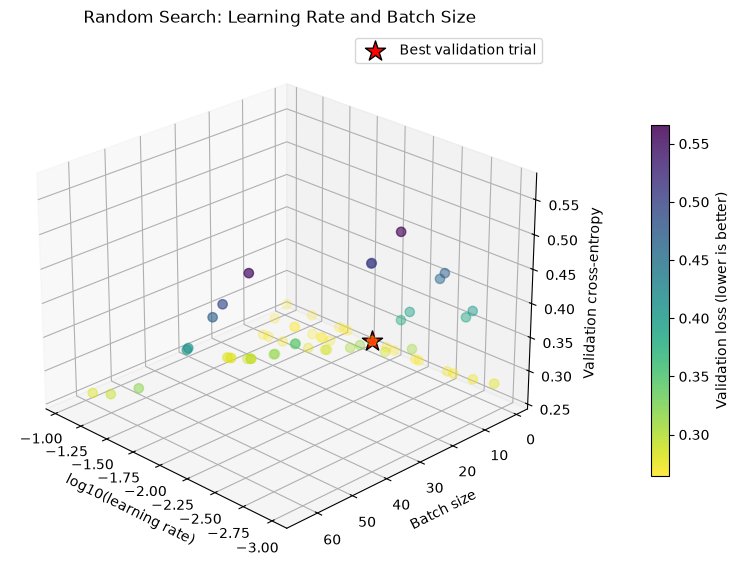

In [14]:
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")
points = ax.scatter(
    np.log10(search_results["learning_rate"]), search_results["batch_size"],
    search_results["validation_loss"], c=search_results["validation_loss"],
    cmap="viridis_r", s=45, alpha=0.85,
)
ax.scatter(
    np.log10(best_trial["learning_rate"]), best_trial["batch_size"],
    best_trial["validation_loss"], color="red", marker="*", s=230,
    edgecolor="black", label="Best validation trial",
)
ax.set_xlabel("log10(learning rate)")
ax.set_ylabel("Batch size")
ax.set_zlabel("Validation cross-entropy")
ax.set_title("Random Search: Learning Rate and Batch Size")
ax.view_init(elev=25, azim=135)
ax.legend()
fig.colorbar(points, ax=ax, shrink=0.65, pad=0.12, label="Validation loss (lower is better)")
plt.show()


## Refit the winner and evaluate once on the test set

Fix the learning rate and batch size using validation loss. Combine training + validation data, recompute scaling on that combined data, and train a fresh model with the selected settings. Keep the original trial models for inspection.

Evaluate the final model once on the held-out cancer test set. Do not use this score to change the settings or search ranges. The winning validation score can be optimistic after many trials; the test score provides a separate final assessment.


In [15]:
x_final_raw = np.concatenate([x_train_raw, x_val_raw])
y_final = np.concatenate([y_sgd_train, y_sgd_val])
final_mean, final_std = x_final_raw.mean(), x_final_raw.std()
x_final = (x_final_raw - final_mean) / final_std
x_final_test = (x_test_raw - final_mean) / final_std
final_w, final_b, _ = fit_logistic_batches(
    x_final, y_final, learning_rate=float(best_trial["learning_rate"]),
    epochs=epochs_sgd, batch_size=int(best_trial["batch_size"]), seed=42
)
final_model = {"w": final_w, "b": final_b, "mean": final_mean, "std": final_std}
final_test_probability = stable_sigmoid(final_w * x_final_test + final_b)
final_test_prediction = (final_test_probability >= 0.5).astype(int)
print(f"Winning trial: {best_trial_id}")
print(f"Learning rate: {best_trial['learning_rate']:.6g}; batch size: {int(best_trial['batch_size'])}")
print(f"Selection validation loss: {best_trial['validation_loss']:.4f}")
selection_val_probability = stable_sigmoid(
    best_search_model["w"] * x_sgd_val + best_search_model["b"]
)
selection_val_prediction = (selection_val_probability >= 0.5).astype(int)
print(f"Selection validation accuracy: {np.mean(selection_val_prediction == y_sgd_val):.3f}")
print(f"Final test loss: {cross_entropy(x_final_test, y_sgd_test, final_w, final_b):.4f}")
print(f"Final test accuracy: {np.mean(final_test_prediction == y_sgd_test):.3f}")


Winning trial: 39
Learning rate: 0.0137241; batch size: 1
Selection validation loss: 0.2647
Selection validation accuracy: 0.886
Final test loss: 0.3293
Final test accuracy: 0.833


## Discussion

1. Why do we apply sigmoid to z=wx+b instead of using z directly for classification?

2. What is the difference between an epoch and a parameter update? How does batch size affect the number of parameter updates per epoch?
3. Can we combine validation + test after choosing the hyperparameters?
